# Sieci Kohonena - Grid

In [3]:
import numpy as np
import pandas as pd
import math
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
from plotly.subplots import make_subplots
import itertools
from matplotlib.patches import RegularPolygon, Rectangle
from sklearn.datasets import fetch_openml

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [4]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

def ij_to_xy(i, j):
    x = j + 0.5 * (i % 2)
    y = i * (np.sqrt(3) / 2)
    return x, y

In [5]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie, topologia):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1
        self.topologia = topologia

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))

        if self.topologia == 'szesciokat':
            x_grid, y_grid = ij_to_xy(i_grid, j_grid)
            best_x, best_y = ij_to_xy(best_coord[0], best_coord[1])
            d2_grid = (x_grid - best_x)**2 + (y_grid - best_y)**2
            
        else:
            d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2

        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in range(self.iteracje):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [6]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [7]:
def mapping_plot_ax(model, dane, etykiety, ax, tytul):
    neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
    etykiety_plaskie = etykiety.flatten()
    
    for idx, x in enumerate(dane):
        bmu_coord = model.znajdz_najblizszy(x)
        neurony_klasy[bmu_coord].append(etykiety_plaskie[idx])
        
    cmap = plt.get_cmap('tab10')
    poprawne_trafienia = 0
    wszystkie_probki = len(dane)
    
    for i in range(model.M):
        for j in range(model.N):
            klasy_w_neuronie = neurony_klasy[(i, j)]
            liczba_punktow = len(klasy_w_neuronie)
            
            if liczba_punktow > 0:
                dominujaca_klasa, liczba_w_dominujacej = Counter(klasy_w_neuronie).most_common(1)[0]
                poprawne_trafienia += liczba_w_dominujacej
                kolor_tla = cmap(dominujaca_klasa)
                alpha_tla = 0.3
            else:
                kolor_tla, alpha_tla = 'white', 1.0
                
            if hasattr(model, 'topologia') and model.topologia == 'szesciokat':
                x_center, y_center = ij_to_xy(i, j)
                promien = 1 / math.sqrt(3) 
                ksztalt = RegularPolygon(
                    (x_center, y_center), numVertices=6, radius=promien, 
                    orientation=math.pi/6,
                    linewidth=1, edgecolor='black', facecolor=kolor_tla, alpha=alpha_tla
                )
            else:
                x_center, y_center = i, j
                ksztalt = Rectangle(
                    (i - 0.5, j - 0.5), 1, 1, 
                    linewidth=1, edgecolor='black', facecolor=kolor_tla, alpha=alpha_tla
                )
                
            ax.add_patch(ksztalt)
            
            if liczba_punktow > 0:
                jx, jy = np.random.uniform(-0.35, 0.35, liczba_punktow), np.random.uniform(-0.35, 0.35, liczba_punktow)
                kolory_kropek = [cmap(k) for k in klasy_w_neuronie]
                ax.scatter(x_center + jx, y_center + jy, c=kolory_kropek, edgecolors='black', s=20, zorder=5)

    accuracy = poprawne_trafienia / wszystkie_probki
    
    if hasattr(model, 'topologia') and model.topologia == 'szesciokat':
        ax.set_xlim(-1, model.N + 0.5)
        ax.set_ylim(-1, model.M * math.sqrt(3)/2 + 0.5)
    else:
        ax.set_xlim(-0.5, model.M - 0.5)
        ax.set_ylim(-0.5, model.N - 0.5)
        
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    
    ax.set_title(f"{tytul}\nAcc: {accuracy*100:.1f}%", fontweight='bold')
    ax.grid(False)
    
    return accuracy

In [8]:
def train_grid(data, y_etykiety, n, NM_lista, sigma_lista, funkcje, topologia, epoki=10, wygaszanie=5):
    modele = []
    df_dane = []

    topologie_sorted = sorted(topologia, key=lambda x: 0 if x == 'szesciokat' else 1)
    funkcje_nazwy = [f.__name__ for f in funkcje]

    kombinacje = list(itertools.product(funkcje, sigma_lista, NM_lista, topologia))
    calkowita_liczba_modeli = len(kombinacje)
        
    pasek_postepu = tqdm(kombinacje, total=calkowita_liczba_modeli, desc="Trening", unit="model")
    
    for funkcja, sig, nm, top in pasek_postepu:
        nazwa_funkcji = funkcja.__name__ 
        tytul = f"{nm}x{nm} | Sigma={sig}\n{nazwa_funkcji} | {top}"
        
        model = Kohonen(nm, nm, n, epoki, sig, funkcja, wygaszanie, top)
        model.train(data)
        
        modele.append({
            'nm': nm, 'sig': sig, 'funkcja': nazwa_funkcji,
            'topologia': top, 'tytul': tytul, 'model': model
        })

    ncols = len(NM_lista)
    nrows = len(topologie_sorted) * len(funkcje) * len(sigma_lista)

    fig_map, axes_map = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 5))
    axes_map = np.atleast_2d(axes_map)
    
    for m in modele:
        c = NM_lista.index(m['nm'])
        
        idx_topo = topologie_sorted.index(m['topologia'])
        idx_funk = funkcje_nazwy.index(m['funkcja'])
        idx_sig = sigma_lista.index(m['sig'])
        
        r = (idx_topo * len(funkcje) * len(sigma_lista)) + \
            (idx_funk * len(sigma_lista)) + \
            idx_sig
        
        ax = axes_map[r, c]
        
        acc = mapping_plot_ax(m['model'], data, y_etykiety, ax, m['tytul'])
        
        df_dane.append({
            'Rozmiar': f"{m['nm']}x{m['nm']}",
            'Sigma': m['sig'],
            'Funkcja': m['funkcja'],
            'Topologia': m['topologia'],
            'Accuracy (%)': round(acc * 100, 2)
        })
        
    for ax in axes_map.flatten():
        if not ax.has_data() and len(ax.patches) == 0:
            ax.axis('off')
            
    plt.tight_layout()
    plt.show()
    
    df = pd.DataFrame(df_dane)
    df = df.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
    return df

In [9]:
def plot_neighborhood_functions(sigma_values_gauss, sigma_values_mexican, max_d=10):
    d = np.linspace(0, max_d, 300)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    for sigma in sigma_values_gauss:
        gauss = funkcja_Gaussa(d**2, sigma)
        axes[0].plot(d, gauss, label=f'sigma={sigma}')
    
    for sigma in sigma_values_mexican:
        mex   = meksykanski_kapelusz(d**2, sigma)
        axes[1].plot(d, mex,   label=f'sigma={sigma}')
    
    axes[0].set_title('Funkcja Gaussowska')
    axes[0].set_xlabel('Odległość od BMU w siatce')
    axes[0].set_ylabel('h(d, sigma)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].set_title('Meksykański kapelusz')
    axes[1].set_xlabel('Odległość od BMU w siatce')
    axes[1].axhline(0, color='k', lw=0.5)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Dane MNIST

In [10]:
mnist = fetch_openml('mnist_784', version=1, parser='auto')

mnist_data = mnist.data.to_numpy() 
y_etykiety = mnist.target.to_numpy().astype(int)

rozmiar_podzbioru = 10000

mnist_data = mnist_data[:rozmiar_podzbioru]
y_etykiety = y_etykiety[:rozmiar_podzbioru]

mnist_data = mnist_data / 255.0 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = mnist_data.shape[1]

In [13]:
NM = [8, 12, 16]
sigma = [0.5, 1, 2, 4, 8, 10]
sigma_gauss = [0.5, 1, 2]
sigma_mexican = [4, 8, 10]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]
topologie = ['szesciokat', 'kwadrat']

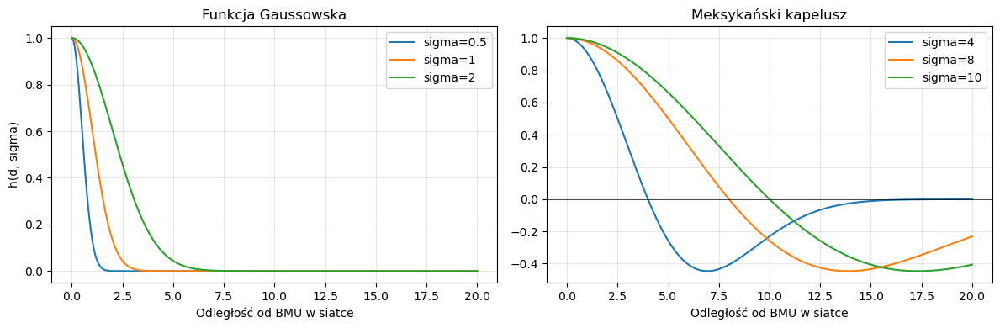

In [18]:
plot_neighborhood_functions(sigma_gauss, sigma_mexican, 20)

In [12]:
sigma = [0.5, 1, 2]
funkcje = [funkcja_Gaussa]

Trening: 100%|██████████| 18/18 [21:16<00:00, 70.93s/model] 


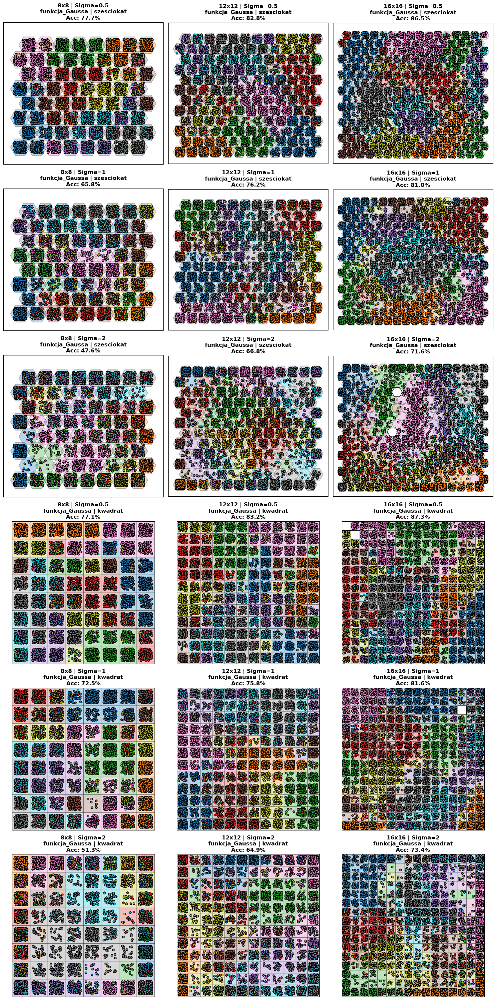

,Rozmiar,Sigma,Funkcja,Topologia,Accuracy (%)
0,16x16,0.5,funkcja_Gaussa,kwadrat,87.28
1,16x16,0.5,funkcja_Gaussa,szesciokat,86.46
2,12x12,0.5,funkcja_Gaussa,kwadrat,83.21
3,12x12,0.5,funkcja_Gaussa,szesciokat,82.83
4,16x16,1.0,funkcja_Gaussa,kwadrat,81.62
5,16x16,1.0,funkcja_Gaussa,szesciokat,80.96
6,8x8,0.5,funkcja_Gaussa,szesciokat,77.68
7,8x8,0.5,funkcja_Gaussa,kwadrat,77.13
8,12x12,1.0,funkcja_Gaussa,szesciokat,76.23
9,12x12,1.0,funkcja_Gaussa,kwadrat,75.76


In [13]:
train_grid(mnist_data, y_etykiety, n, NM, sigma, funkcje, topologie, epoki=4, wygaszanie=2)

In [14]:
sigma = [4, 8, 10]
funkcje = [meksykanski_kapelusz]

Trening: 100%|██████████| 18/18 [23:57<00:00, 79.88s/model] 


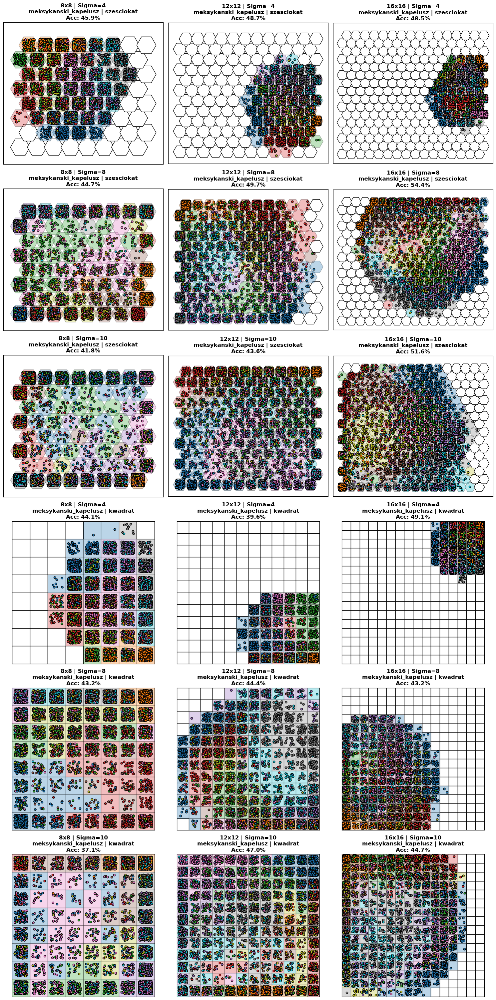

,Rozmiar,Sigma,Funkcja,Topologia,Accuracy (%)
0,16x16,8,meksykanski_kapelusz,szesciokat,54.36
1,16x16,10,meksykanski_kapelusz,szesciokat,51.56
2,12x12,8,meksykanski_kapelusz,szesciokat,49.66
3,16x16,4,meksykanski_kapelusz,kwadrat,49.07
4,12x12,4,meksykanski_kapelusz,szesciokat,48.72
5,16x16,4,meksykanski_kapelusz,szesciokat,48.51
6,12x12,10,meksykanski_kapelusz,kwadrat,47.02
7,8x8,4,meksykanski_kapelusz,szesciokat,45.92
8,8x8,8,meksykanski_kapelusz,szesciokat,44.72
9,16x16,10,meksykanski_kapelusz,kwadrat,44.67


In [15]:
train_grid(mnist_data, y_etykiety, n, NM, sigma, funkcje, topologie, epoki=4, wygaszanie=2)

# Dane HAR

In [16]:
har_data = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/X_train.txt", sep=r'\s+', header=None)
y_etykiety = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/y_train.txt", sep=r'\s+', header=None)

har_data = har_data.to_numpy() 
y_etykiety = y_etykiety.to_numpy().astype(int) - 1 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = har_data.shape[1]
ncols = har_data.shape[0]

In [17]:
NM = [5, 10, 15]
sigma = [0.5, 1, 2, 4, 8, 10]
funkcje = [funkcja_Gaussa, meksykanski_kapelusz]
topologie = ['szesciokat', 'kwadrat']

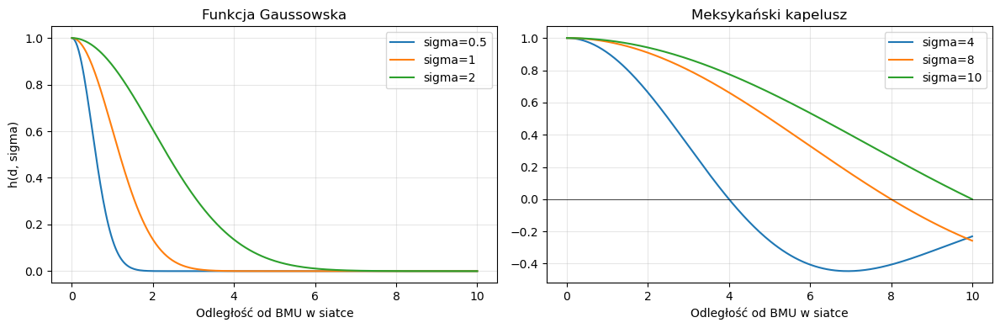

In [17]:
plot_neighborhood_functions(sigma_gauss, sigma_mexican)

In [19]:
sigma = [0.5, 1, 2]
funkcje = [funkcja_Gaussa]

Trening: 100%|██████████| 18/18 [12:02<00:00, 40.16s/model]


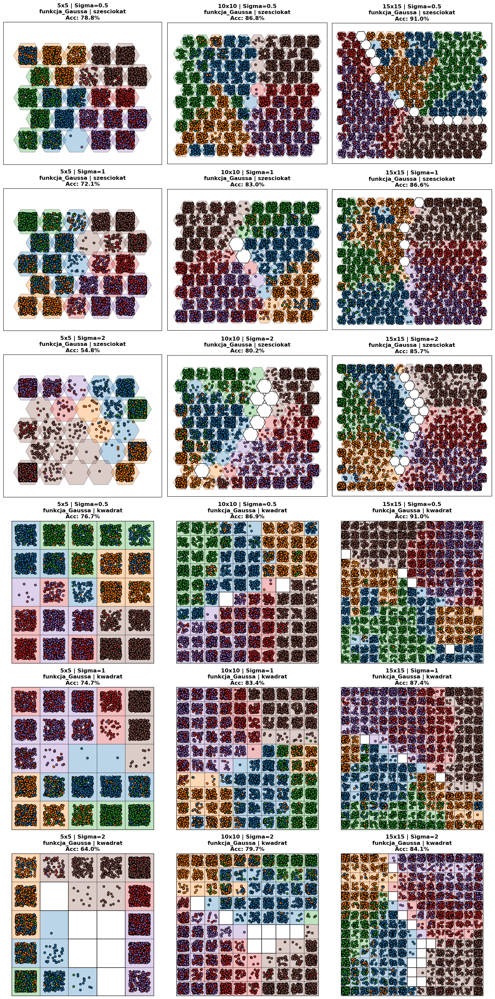

,Rozmiar,Sigma,Funkcja,Topologia,Accuracy (%)
0,15x15,0.5,funkcja_Gaussa,szesciokat,90.98
1,15x15,0.5,funkcja_Gaussa,kwadrat,90.95
2,15x15,1.0,funkcja_Gaussa,kwadrat,87.43
3,10x10,0.5,funkcja_Gaussa,kwadrat,86.87
4,10x10,0.5,funkcja_Gaussa,szesciokat,86.78
5,15x15,1.0,funkcja_Gaussa,szesciokat,86.60
6,15x15,2.0,funkcja_Gaussa,szesciokat,85.70
7,15x15,2.0,funkcja_Gaussa,kwadrat,84.07
8,10x10,1.0,funkcja_Gaussa,kwadrat,83.39
9,10x10,1.0,funkcja_Gaussa,szesciokat,82.98


In [20]:
train_grid(har_data, y_etykiety, n, NM, sigma, funkcje, topologie)

In [21]:
sigma = [4, 8, 10]
funkcje = [meksykanski_kapelusz]

Trening: 100%|██████████| 18/18 [07:32<00:00, 25.12s/model]


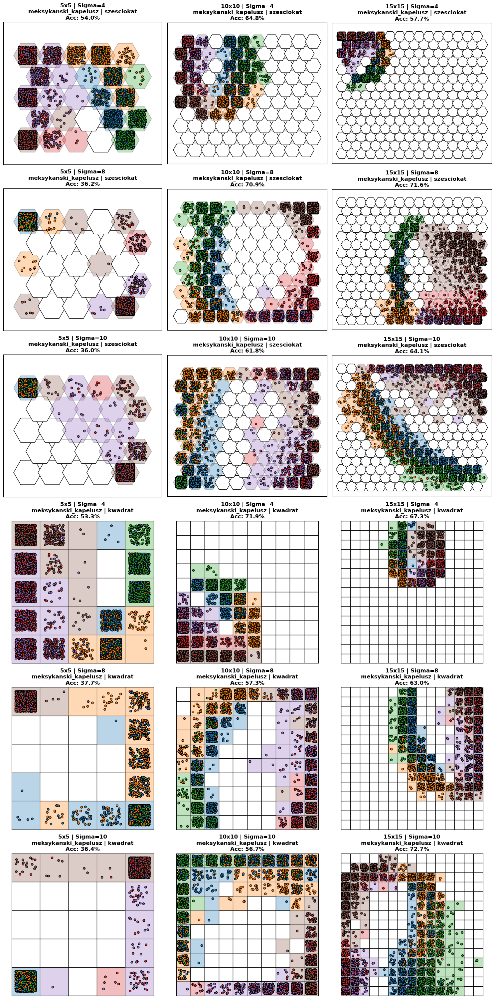

,Rozmiar,Sigma,Funkcja,Topologia,Accuracy (%)
0,15x15,10,meksykanski_kapelusz,kwadrat,72.66
1,10x10,4,meksykanski_kapelusz,kwadrat,71.93
2,15x15,8,meksykanski_kapelusz,szesciokat,71.56
3,10x10,8,meksykanski_kapelusz,szesciokat,70.95
4,15x15,4,meksykanski_kapelusz,kwadrat,67.26
5,10x10,4,meksykanski_kapelusz,szesciokat,64.79
6,15x15,10,meksykanski_kapelusz,szesciokat,64.08
7,15x15,8,meksykanski_kapelusz,kwadrat,63.04
8,10x10,10,meksykanski_kapelusz,szesciokat,61.77
9,15x15,4,meksykanski_kapelusz,szesciokat,57.67


In [22]:
train_grid(har_data, y_etykiety, n, NM, sigma, funkcje, topologie)